# ξ(s, μ), multipoles and w_p(r_p) from m of k partitions

The anisotropic estimators take the same arguments as `compute_xi`. The line
of sight is the z axis.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from pysauce import compute_2pcf, compute_xi_smu

## A mock catalogue in redshift space

The mock is the one of `01_xi_r.ipynb`. To put it in redshift space each
galaxy is moved along z by its line-of-sight velocity divided by the Hubble
rate, here a random displacement of 3 Mpc/h (rms), which stretches the haloes
along the line of sight. Positions must be wrapped back into the box.

In [2]:
def clustered_mock(n_haloes, mean_members, halo_size, box_size, k, rng):
    """Galaxies scattered around randomly placed haloes.

    Every galaxy of a halo gets that halo's partition label, as when each
    partition holds the galaxies of one file of merger trees.
    """
    centres = rng.uniform(0, box_size, (n_haloes, 3))
    halo = np.repeat(np.arange(n_haloes), rng.poisson(mean_members, n_haloes))
    coords = (centres[halo] + rng.normal(0, halo_size, (len(halo), 3))) % box_size
    coords[coords >= box_size] = 0.0  # the modulo can round up to box_size
    partition_ids = rng.integers(0, k, n_haloes, dtype=np.int32)[halo]
    return coords, partition_ids


BOX_SIZE = 500.0  # Mpc/h
K = 8             # partitions in the full catalogue

rng = np.random.default_rng(1)
coords, partition_ids = clustered_mock(40_000, 5, 1.0, BOX_SIZE, K, rng)
print(f"{len(coords):,} galaxies in {K} partitions")

coords[:, 2] = (coords[:, 2] + rng.normal(0, 3.0, len(coords))) % BOX_SIZE
coords[coords >= BOX_SIZE] = 0.0

199,659 galaxies in 8 partitions


In [3]:
def select(chosen):
    """The galaxies of the chosen partitions."""
    keep = np.isin(partition_ids, chosen)
    return coords[keep], partition_ids[keep]


M = 2
sparse_catalogue = select([0, 1])

## ξ(s, μ) and its multipoles

`compute_xi_smu` bins pairs by separation s and by μ = |Δz| / s, and returns
the grid `xi_smu` with the monopole `xi0` and quadrupole `xi2`.

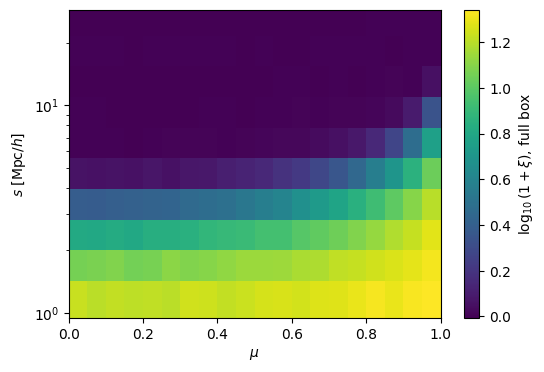

In [4]:
s_bins = np.logspace(0, np.log10(30.0), 11)

full = compute_xi_smu(
    coords, partition_ids, s_bins, BOX_SIZE,
    n_partitions=K, n_partitions_selected=K, n_mu_bins=20,
)
sparse = compute_xi_smu(
    *sparse_catalogue, s_bins, BOX_SIZE,
    n_partitions=K, n_partitions_selected=M, n_mu_bins=20,
)

fig, ax = plt.subplots(figsize=(6, 4))
mesh = ax.pcolormesh(full["mu_mid"], full["s_mid"], np.log10(1 + full["xi_smu"]), shading="nearest")
ax.set_yscale("log")
ax.set_xlabel(r"$\mu$")
ax.set_ylabel(r"$s$ [Mpc/$h$]")
fig.colorbar(mesh, label=r"$\log_{10}(1 + \xi)$, full box")
plt.show()

The displacements move pairs towards the line of sight (μ near 1), so the
quadrupole is positive on these scales.

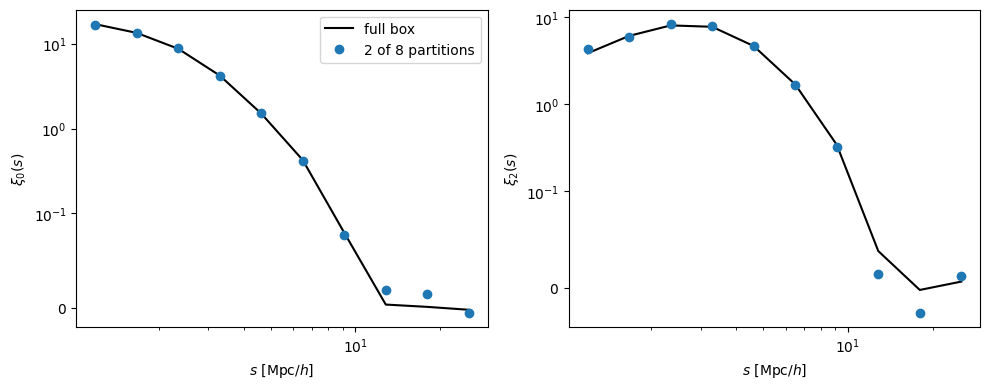

In [5]:
s = full["s_mid"]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, key, label in zip(axes, ["xi0", "xi2"], [r"$\xi_0(s)$", r"$\xi_2(s)$"]):
    ax.semilogx(s, full[key], "k-", label="full box")
    ax.semilogx(s, sparse[key], "o", label=f"{M} of {K} partitions")
    ax.set_yscale("symlog", linthresh=0.1)
    ax.set_xlabel(r"$s$ [Mpc/$h$]")
    ax.set_ylabel(label)
axes[0].legend()
fig.tight_layout()
plt.show()

## ξ(r_p, π) and w_p(r_p)

`compute_2pcf` bins pairs by transverse separation r_p and line-of-sight
separation π, and integrates over π to give the projected correlation
function `wp`. Its random counts are those of the full catalogue, whose
number of galaxies is taken to be N k / m unless `n_total` is given. The mock
has no clustering beyond its haloes, so only small r_p is shown.

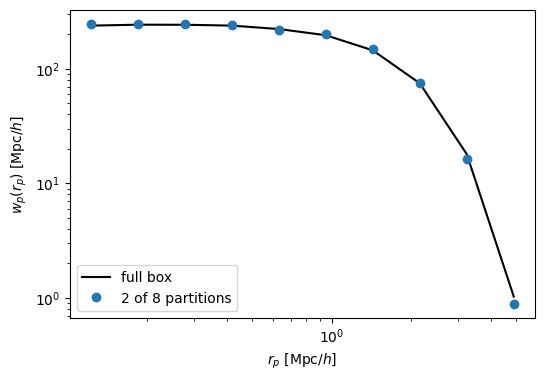

In [6]:
rp_bins = np.logspace(-1, np.log10(6.0), 11)
pi_bins = np.arange(0.0, 41.0)

full_2d = compute_2pcf(
    coords, partition_ids, rp_bins, pi_bins, BOX_SIZE,
    n_partitions=K, n_partitions_selected=K,
)
sparse_2d = compute_2pcf(
    *sparse_catalogue, rp_bins, pi_bins, BOX_SIZE,
    n_partitions=K, n_partitions_selected=M, n_total=len(coords),
)

rp = np.sqrt(rp_bins[:-1] * rp_bins[1:])
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(rp, full_2d["wp"], "k-", label="full box")
ax.loglog(rp, sparse_2d["wp"], "o", label=f"{M} of {K} partitions")
ax.set_xlabel(r"$r_p$ [Mpc/$h$]")
ax.set_ylabel(r"$w_p(r_p)$ [Mpc/$h$]")
ax.legend()
plt.show()